# Milestone 3: Temporal Analysis, Advanced EDA, dan Visualisasi Interaktif

**Dataset:** Indonesian Regulation Knowledge Graph  
**Input:** hasil cleaning Milestone 2 (`id_reg_kg_2511_cleaned`)  
**Teknik:** Polars LazyFrame, window function, Plotly Express, dan Plotly Graph Objects.

Notebook ini disusun berdasarkan struktur dataset Milestone 1 dan hasil cleaning Milestone 2. Dataset berisi 748.558 record dalam 75 file Parquet dengan 41 kolom awal. Karena ukuran hasil cleaning sekitar 2,92 GiB, analisis menggunakan `scan_parquet()` agar hanya kolom yang diperlukan yang dibaca.

**Target Milestone 3:**
1. Analisis temporal menggunakan agregasi tahunan dan moving average 5 tahun.
2. Minimal 6 visualisasi interaktif.
3. Minimal 5 insight analitik berdasarkan hasil aktual.

**Catatan interpretasi:** dataset memiliki `chunk_id` dan berisi potongan teks peraturan. Karena itu, grafik jumlah tahunan dibaca sebagai jumlah record/chunk dalam dataset, bukan otomatis jumlah undang-undang atau dokumen hukum yang unik. Dataset juga tidak menyediakan koordinat geografis, sehingga analisis multidimensi menggunakan skor dan metadata knowledge graph sebagai pengganti analisis spasial.


## Bagian 1. Inisialisasi dan Memuat Data Hasil Cleaning

Pastikan folder hasil Milestone 2 tersedia. Path di bawah mengikuti lokasi yang tercatat pada notebook Milestone 2. Jika folder berada di lokasi lain, ubah `DATA_DIR` saja.


In [1]:
from pathlib import Path

import polars as pl
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# Lokasi output Milestone 2
DATA_DIR = Path(r"C:\Users\raihan bhakti\id_reg_kg_2511_cleaned")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Folder hasil cleaning tidak ditemukan: {DATA_DIR}. "
        "Periksa kembali DATA_DIR sesuai lokasi dataset di laptop."
    )

parquet_files = sorted(DATA_DIR.glob("*.parquet"))

if not parquet_files:
    raise FileNotFoundError(
        f"Tidak ditemukan file Parquet di: {DATA_DIR}"
    )

# Lazy loading: tidak memuat seluruh dataset ke RAM
lf = pl.scan_parquet([str(file) for file in parquet_files])
schema = lf.collect_schema()

print("Versi Polars:", pl.__version__)
print("Jumlah file Parquet:", len(parquet_files))
print("Jumlah kolom:", len(schema))
print("\nSchema dataset:")
print(schema)

total_record = (
    lf.select(pl.len().alias("total_record"))
    .collect(engine="streaming")
    .item()
)

print(f"\nJumlah record hasil cleaning: {total_record:,}")


Versi Polars: 2.0.0
Jumlah file Parquet: 75
Jumlah kolom: 44

Schema dataset:
Schema([('global_id', Int64), ('local_id', Int64), ('regulation_type', String), ('enacting_body', String), ('regulation_number', String), ('year', Int32), ('about', String), ('effective_date', String), ('chapter', String), ('article', String), ('content', String), ('chunk_id', Int64), ('embedding', List(Float64)), ('tfidf_vector', List(Float64)), ('__index_level_0__', Int64), ('kg_entities_json', String), ('kg_entity_count', Int64), ('kg_cross_references_json', String), ('kg_cross_ref_count', Int64), ('kg_legal_domains_json', String), ('kg_primary_domain', String), ('kg_domain_confidence', Float64), ('kg_concept_clusters_json', String), ('kg_cluster_count', Int64), ('kg_cluster_diversity', Float64), ('kg_authority_score', Float64), ('kg_hierarchy_level', Int64), ('kg_temporal_score', Float64), ('kg_years_old', Int64), ('kg_legal_richness', Float64), ('kg_legal_complexity', Float64), ('kg_legal_actions_json', 

## Bagian 2. Pemeriksaan Awal Dataset Bersih

Pemeriksaan ini memastikan kolom yang dipakai pada analisis Milestone 3 tersedia. Kolom embedding dan vektor tidak dimuat karena tidak diperlukan untuk visualisasi ini.


In [2]:
kolom_analisis = [
    "global_id",
    "year",
    "year_status",
    "regulation_type",
    "enacting_body",
    "content",
    "kg_primary_domain",
    "kg_entity_count",
    "kg_cross_ref_count",
    "kg_domain_confidence",
    "kg_cluster_count",
    "kg_cluster_diversity",
    "kg_authority_score",
    "kg_hierarchy_level",
    "kg_temporal_score",
    "kg_years_old",
    "kg_legal_richness",
    "kg_legal_complexity",
    "kg_completeness_score",
    "kg_connectivity_score",
]

kolom_tidak_ada = [
    kolom for kolom in kolom_analisis
    if kolom not in schema
]

if kolom_tidak_ada:
    raise ValueError(
        f"Kolom yang dibutuhkan tidak ditemukan: {kolom_tidak_ada}"
    )

ringkasan_awal = lf.select([
    pl.len().alias("total_record"),
    pl.col("global_id").n_unique().alias("global_id_unik"),
    pl.col("year").null_count().alias("year_null"),
    pl.col("regulation_type").null_count().alias("regulation_type_null"),
    pl.col("enacting_body").null_count().alias("enacting_body_null"),
    pl.col("content").null_count().alias("content_null"),
]).collect(engine="streaming")

display(ringkasan_awal)

preview = (
    lf.select([
        "global_id",
        "regulation_type",
        "enacting_body",
        "year",
        "year_status",
        "kg_primary_domain",
        "kg_legal_complexity",
        "kg_authority_score",
    ])
    .head(10)
    .collect(engine="streaming")
)

display(preview)


total_record,global_id_unik,year_null,regulation_type_null,enacting_body_null,content_null
u32,u32,u32,u32,u32,u32
748558,748558,567,79764,64521,0


global_id,regulation_type,enacting_body,year,year_status,kg_primary_domain,kg_legal_complexity,kg_authority_score
i64,str,str,i32,str,str,f64,f64
0,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""tax""",0.31,0.72
1,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""tax""",0.26,0.72
2,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""tax""",0.205,0.72
3,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""general""",0.395,0.72
4,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""tax""",0.335,0.72
5,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""tax""",0.335,0.72
6,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""general""",0.31,0.72
7,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""criminal""",0.418333,0.72
8,"""PERATURAN PEMERINTAH""","""REPUBLIK INDONESIA""",2009,"""ok""","""criminal""",0.393333,0.72


## Bagian 3. Analisis Temporal dan Window Function

Kolom `year` digunakan sebagai dimensi waktu karena sudah dinormalisasi menjadi numerik pada Milestone 2. Analisis utama hanya menggunakan `year_status == "ok"`. Dengan demikian, 567 nilai tahun sentinel `0000` dan 2 record bertahun 2030 yang ditandai untuk pemeriksaan tidak dicampurkan ke tren historis.

Data dilengkapi dengan rentang tahun berurutan agar `rolling_mean(window_size=5)` merepresentasikan moving average lima tahun kalender.


In [3]:
# Agregasi jumlah record per tahun
data_tahunan = (
    lf.filter(
        (pl.col("year_status") == "ok")
        & pl.col("year").is_not_null()
    )
    .group_by("year")
    .agg(
        pl.len().alias("jumlah_record")
    )
    .sort("year")
    .collect(engine="streaming")
)

if data_tahunan.is_empty():
    raise ValueError("Tidak ada data dengan year_status == 'ok'.")

# Melengkapi tahun yang tidak memiliki record agar rolling window
# tetap merepresentasikan lima tahun kalender
tahun_lengkap = pl.DataFrame({
    "year": list(
        range(
            int(data_tahunan["year"].min()),
            int(data_tahunan["year"].max()) + 1
        )
    )
})

data_tahunan = (
    tahun_lengkap
    .join(data_tahunan, on="year", how="left")
    .with_columns(
        pl.col("jumlah_record").fill_null(0).cast(pl.Int64)
    )
    .sort("year")
    .with_columns([
        pl.col("jumlah_record")
        .rolling_mean(window_size=5, min_samples=1)
        .alias("moving_average_5_tahun"),

        (
            pl.col("jumlah_record")
            - pl.col("jumlah_record").shift(1)
        ).alias("perubahan_dari_tahun_sebelumnya"),

        pl.when(pl.col("jumlah_record").shift(1) > 0)
        .then(
            (
                pl.col("jumlah_record")
                - pl.col("jumlah_record").shift(1)
            )
            / pl.col("jumlah_record").shift(1)
            * 100
        )
        .otherwise(None)
        .alias("pertumbuhan_persen"),
    ])
)

print("Ringkasan agregasi tahunan:")
display(data_tahunan)

print("Tahun dengan record terbanyak:")
display(
    data_tahunan
    .sort("jumlah_record", descending=True)
    .head(10)
)


Ringkasan agregasi tahunan:


year,jumlah_record,moving_average_5_tahun,perubahan_dari_tahun_sebelumnya,pertumbuhan_persen
i64,i64,f64,i64,f64
1945,5156,5156.0,null,null
1946,430,2793.0,-4726,-91.660202
1947,793,2126.333333,363,84.418605
1948,1357,1934.0,564,71.12232
1949,328,1612.8,-1029,-75.829035
…,…,…,…,…
2016,117505,81553.2,28766,32.416412
2017,49833,79821.4,-67672,-57.590741
2018,97,66606.2,-49736,-99.80535


Tahun dengan record terbanyak:


year,jumlah_record,moving_average_5_tahun,perubahan_dari_tahun_sebelumnya,pertumbuhan_persen
i64,i64,f64,i64,f64
2016,117505,81553.2,28766,32.416412
2015,88739,71581.4,11882,15.45988
2014,76857,60265.4,10684,16.145558
2011,67646,33658.8,35487,110.34858
2013,66173,50814.8,7681,13.13171
2012,58492,42756.6,-9154,-13.532212
2017,49833,79821.4,-67672,-57.590741
2010,32159,22243.4,2555,8.63059
2009,29604,17693.6,3722,14.380651


## Bagian 4. Visualisasi Interaktif

### Visualisasi 1. Tren jumlah record per tahun

Grafik menampilkan jumlah record/chunk per tahun dan moving average lima tahun. Range slider digunakan untuk memperbesar rentang tahun tertentu.


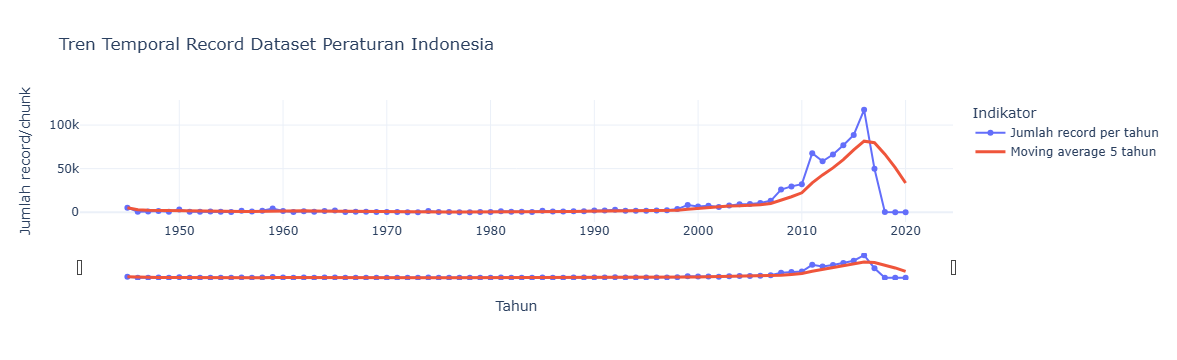

In [4]:
fig1 = go.Figure()

fig1.add_trace(go.Scatter(
    x=data_tahunan["year"].to_list(),
    y=data_tahunan["jumlah_record"].to_list(),
    mode="lines+markers",
    name="Jumlah record per tahun",
    hovertemplate="Tahun: %{x}<br>Jumlah record: %{y:,}<extra></extra>"
))

fig1.add_trace(go.Scatter(
    x=data_tahunan["year"].to_list(),
    y=data_tahunan["moving_average_5_tahun"].to_list(),
    mode="lines",
    name="Moving average 5 tahun",
    line=dict(width=3),
    hovertemplate="Tahun: %{x}<br>MA 5 tahun: %{y:,.2f}<extra></extra>"
))

fig1.update_layout(
    title="Tren Temporal Record Dataset Peraturan Indonesia",
    xaxis_title="Tahun",
    yaxis_title="Jumlah record/chunk",
    hovermode="x unified",
    template="plotly_white",
    legend_title="Indikator"
)

fig1.update_xaxes(rangeslider_visible=True)
fig1.show()


### Visualisasi 2. Distribusi panjang konten peraturan

Panjang konten dihitung dalam karakter. Sampel maksimal 50.000 record digunakan untuk visualisasi agar grafik tetap responsif. Statistik ringkasan tetap dihitung dari seluruh record.


minimum,median,rata_rata,persentil_90,persentil_95,maksimum
u32,f64,f64,f64,f64,u32
3,421.0,1234.325748,2430.0,4570.0,32767


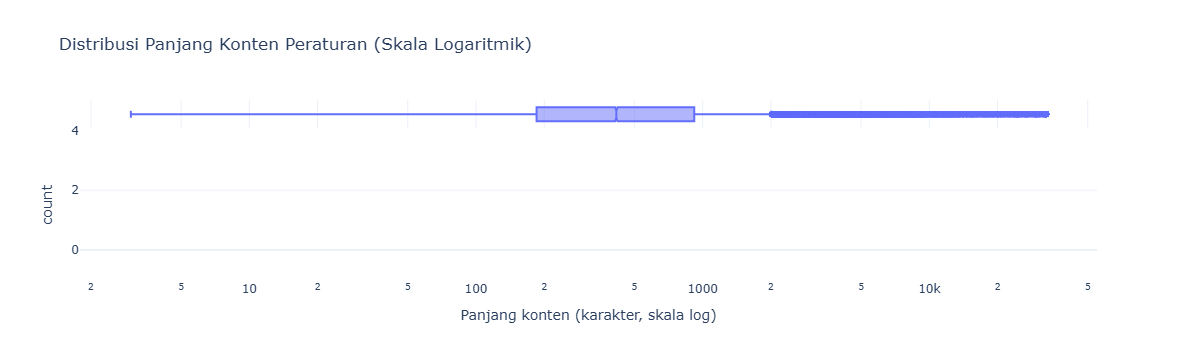

In [5]:
panjang_konten = (
    lf.select(
        pl.col("content")
        .str.len_chars()
        .alias("content_chars")
    )
    .collect(engine="streaming")
)

statistik_panjang = panjang_konten.select([
    pl.col("content_chars").min().alias("minimum"),
    pl.col("content_chars").median().alias("median"),
    pl.col("content_chars").mean().alias("rata_rata"),
    pl.col("content_chars").quantile(0.90).alias("persentil_90"),
    pl.col("content_chars").quantile(0.95).alias("persentil_95"),
    pl.col("content_chars").max().alias("maksimum"),
])

display(statistik_panjang)

sampel_panjang = (
    panjang_konten
    .filter(pl.col("content_chars") > 0)
    .sample(
        n=min(50000, panjang_konten.filter(
            pl.col("content_chars") > 0
        ).height),
        seed=42
    )
)

fig2 = px.histogram(
    x=sampel_panjang["content_chars"].to_list(),
    nbins=60,
    marginal="box",
    log_x=True,
    title="Distribusi Panjang Konten Peraturan (Skala Logaritmik)",
    labels={
        "x": "Panjang konten (karakter, skala log)",
        "y": "Frekuensi"
    }
)

fig2.update_layout(template="plotly_white")
fig2.show()


### Visualisasi 3. Korelasi variabel numerik Knowledge Graph

Korelasi dihitung dari sampel maksimal 50.000 record lengkap pada variabel numerik terpilih. Variabel yang konstan atau tidak memiliki variasi dikeluarkan dari matriks.


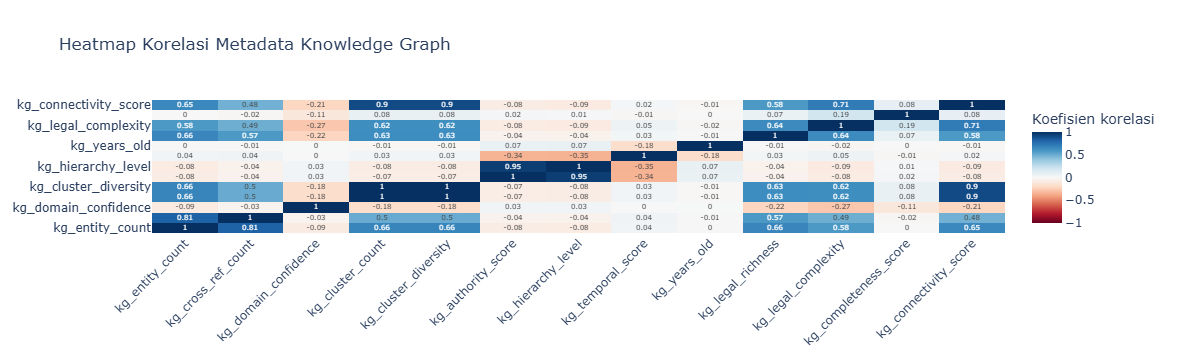

In [6]:
kolom_numerik = [
    "kg_entity_count",
    "kg_cross_ref_count",
    "kg_domain_confidence",
    "kg_cluster_count",
    "kg_cluster_diversity",
    "kg_authority_score",
    "kg_hierarchy_level",
    "kg_temporal_score",
    "kg_years_old",
    "kg_legal_richness",
    "kg_legal_complexity",
    "kg_completeness_score",
    "kg_connectivity_score",
]

data_korelasi = (
    lf.select([
        pl.col(kolom).cast(pl.Float64).alias(kolom)
        for kolom in kolom_numerik
    ])
    .drop_nulls()
    .collect(engine="streaming")
)

if data_korelasi.height < 2:
    raise ValueError(
        "Data lengkap untuk analisis korelasi kurang dari dua record."
    )

sampel_korelasi = data_korelasi.sample(
    n=min(50000, data_korelasi.height),
    seed=42
)

array_korelasi = sampel_korelasi.to_numpy()
standar_deviasi = np.std(array_korelasi, axis=0)

kolom_valid = [
    nama for nama, std in zip(kolom_numerik, standar_deviasi)
    if std > 0
]
array_valid = array_korelasi[:, standar_deviasi > 0]

if len(kolom_valid) < 2:
    raise ValueError(
        "Kurang dari dua variabel memiliki variasi untuk korelasi."
    )

matriks_korelasi = np.corrcoef(
    array_valid,
    rowvar=False
)

fig3 = go.Figure(data=go.Heatmap(
    z=matriks_korelasi,
    x=kolom_valid,
    y=kolom_valid,
    zmin=-1,
    zmax=1,
    colorscale="RdBu",
    text=np.round(matriks_korelasi, 2),
    texttemplate="%{text}",
    colorbar_title="Koefisien korelasi"
))

fig3.update_layout(
    title="Heatmap Korelasi Metadata Knowledge Graph",
    template="plotly_white",
    xaxis_tickangle=-45
)

fig3.show()


### Visualisasi 4. Komposisi jenis peraturan

Kategori null ditampilkan sebagai `Tidak diketahui` agar proporsi metadata yang belum terisi tetap terlihat dan tidak tersembunyi.


regulation_type,jumlah_record
str,u32
"""PERATURAN DAERAH KABUPATEN""",261899
"""PERATURAN BUPATI""",109002
"""Tidak diketahui""",79764
"""PERATURAN DAERAH KOTA""",71978
"""PERATURAN PEMERINTAH""",46280
…,…
"""KEPUTUSAN PRESIDEN""",16133
"""PERATURAN DAERAH""",12876
"""UNDANG UNDANG""",432


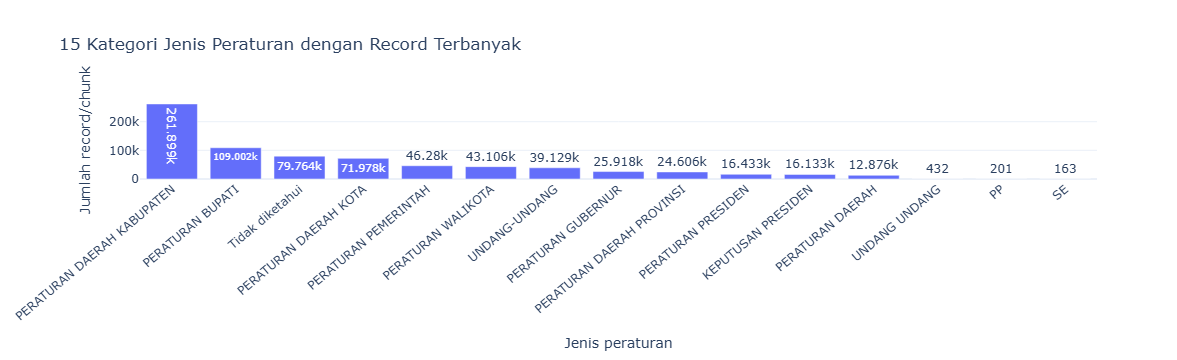

In [7]:
distribusi_jenis = (
    lf.select(
        pl.col("regulation_type")
        .fill_null("Tidak diketahui")
        .alias("regulation_type")
    )
    .group_by("regulation_type")
    .agg(pl.len().alias("jumlah_record"))
    .sort("jumlah_record", descending=True)
    .head(15)
    .collect(engine="streaming")
)

display(distribusi_jenis)

fig4 = px.bar(
    x=distribusi_jenis["regulation_type"].to_list(),
    y=distribusi_jenis["jumlah_record"].to_list(),
    text_auto=True,
    title="15 Kategori Jenis Peraturan dengan Record Terbanyak",
    labels={
        "x": "Jenis peraturan",
        "y": "Jumlah record/chunk"
    }
)

fig4.update_layout(
    template="plotly_white",
    xaxis_tickangle=-40
)
fig4.show()


### Visualisasi 5. Perbandingan domain hukum antar tahun

Heatmap membandingkan jumlah record pada domain hukum utama (`kg_primary_domain`) dari tahun ke tahun. Hanya tahun dengan status `ok` yang digunakan. Sepuluh domain teratas ditampilkan agar pola lebih mudah dibaca.


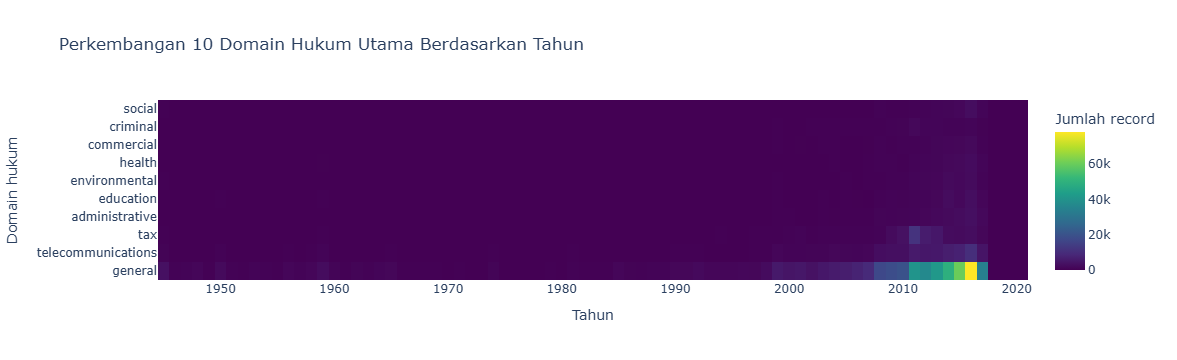

In [8]:
# Menentukan 10 domain utama berdasarkan jumlah record
domain_tahunan_lf = (
    lf.filter(
        (pl.col("year_status") == "ok")
        & pl.col("year").is_not_null()
    )
    .select([
        "year",
        pl.col("kg_primary_domain")
        .fill_null("Tidak diklasifikasikan")
        .alias("domain")
    ])
)

top_domain = (
    domain_tahunan_lf
    .group_by("domain")
    .agg(pl.len().alias("jumlah_record"))
    .sort("jumlah_record", descending=True)
    .head(10)
    .collect(engine="streaming")
)

daftar_domain = top_domain["domain"].to_list()

heatmap_data = (
    domain_tahunan_lf
    .filter(pl.col("domain").is_in(daftar_domain))
    .group_by(["year", "domain"])
    .agg(pl.len().alias("jumlah_record"))
    .collect(engine="streaming")
)

daftar_tahun = sorted(heatmap_data["year"].unique().to_list())
daftar_domain = top_domain["domain"].to_list()

indeks_tahun = {
    tahun: i for i, tahun in enumerate(daftar_tahun)
}
indeks_domain = {
    domain: i for i, domain in enumerate(daftar_domain)
}

matriks_domain = np.zeros(
    (len(daftar_domain), len(daftar_tahun)),
    dtype=int
)

for baris in heatmap_data.iter_rows(named=True):
    i = indeks_domain[baris["domain"]]
    j = indeks_tahun[baris["year"]]
    matriks_domain[i, j] = baris["jumlah_record"]

fig5 = go.Figure(data=go.Heatmap(
    z=matriks_domain,
    x=daftar_tahun,
    y=daftar_domain,
    colorscale="Viridis",
    colorbar_title="Jumlah record"
))

fig5.update_layout(
    title="Perkembangan 10 Domain Hukum Utama Berdasarkan Tahun",
    xaxis_title="Tahun",
    yaxis_title="Domain hukum",
    template="plotly_white"
)

fig5.show()


### Visualisasi 6. Analisis multidimensi kompleksitas dan otoritas hukum

Dataset tidak memiliki koordinat geografis, sehingga visualisasi keenam menggunakan pendekatan multidimensi. Setiap titik mewakili domain hukum. Sumbu X menunjukkan rata-rata kompleksitas hukum, sumbu Y menunjukkan rata-rata authority score, dan ukuran gelembung menunjukkan jumlah record.


kg_primary_domain,jumlah_record,rata_kompleksitas,rata_authority,rata_legal_richness,rata_completeness
str,u32,f64,f64,f64,f64
"""general""",487799,0.199422,0.416435,0.055396,0.818855
"""telecommunications""",66647,0.365469,0.35798,0.252215,0.792112
"""tax""",43564,0.317741,0.363787,0.157557,0.839245
"""administrative""",17396,0.319873,0.38594,0.188167,0.84514
"""education""",14975,0.265085,0.405829,0.142711,0.845649
…,…,…,…,…,…
"""emergency""",5126,0.281001,0.374877,0.134657,0.846547
"""investment""",4573,0.286525,0.439805,0.14286,0.848087
"""maritime""",3522,0.269274,0.451516,0.127144,0.841667


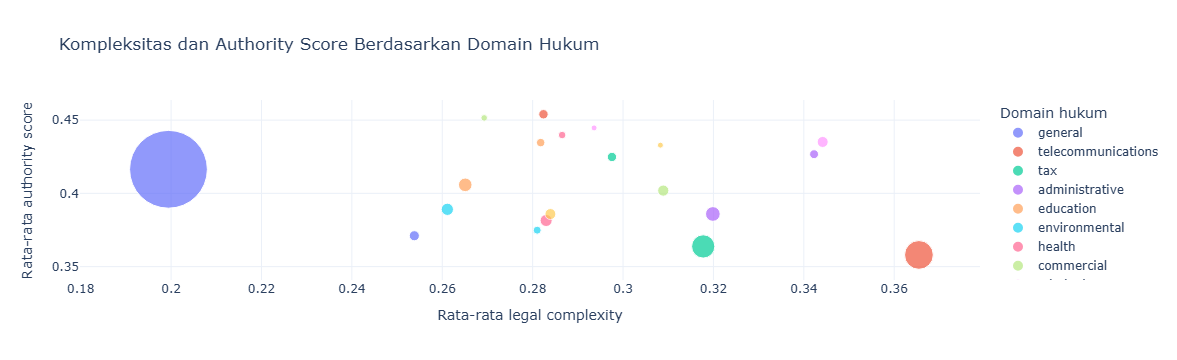

In [9]:
domain_metrics = (
    lf.filter(
        pl.col("kg_primary_domain").is_not_null()
        & pl.col("kg_legal_complexity").is_not_null()
        & pl.col("kg_authority_score").is_not_null()
    )
    .group_by("kg_primary_domain")
    .agg([
        pl.len().alias("jumlah_record"),
        pl.col("kg_legal_complexity")
        .mean().alias("rata_kompleksitas"),
        pl.col("kg_authority_score")
        .mean().alias("rata_authority"),
        pl.col("kg_legal_richness")
        .mean().alias("rata_legal_richness"),
        pl.col("kg_completeness_score")
        .mean().alias("rata_completeness"),
    ])
    .sort("jumlah_record", descending=True)
    .head(20)
    .collect(engine="streaming")
)

display(domain_metrics)

fig6 = px.scatter(
    x=domain_metrics["rata_kompleksitas"].to_list(),
    y=domain_metrics["rata_authority"].to_list(),
    size=domain_metrics["jumlah_record"].to_list(),
    color=domain_metrics["kg_primary_domain"].to_list(),
    hover_name=domain_metrics["kg_primary_domain"].to_list(),
    size_max=55,
    title="Kompleksitas dan Authority Score Berdasarkan Domain Hukum",
    labels={
        "x": "Rata-rata legal complexity",
        "y": "Rata-rata authority score",
        "color": "Domain hukum",
        "size": "Jumlah record"
    }
)

fig6.update_layout(template="plotly_white")
fig6.show()


### Visualisasi tambahan. Lembaga penerbit peraturan

Grafik tambahan ini tidak menggantikan enam visualisasi utama. Tujuannya memperlihatkan konsentrasi record berdasarkan lembaga penerbit.


enacting_body,jumlah_record
str,u32
"""REPUBLIK INDONESIA""",114180
"""MA""",81218
"""Tidak diketahui""",64521
"""RI""",64362
"""BUPATI""",33404
…,…
"""PONTIANAK""",4994
"""GORONTALO""",4930
"""TRENGGALEK""",4784


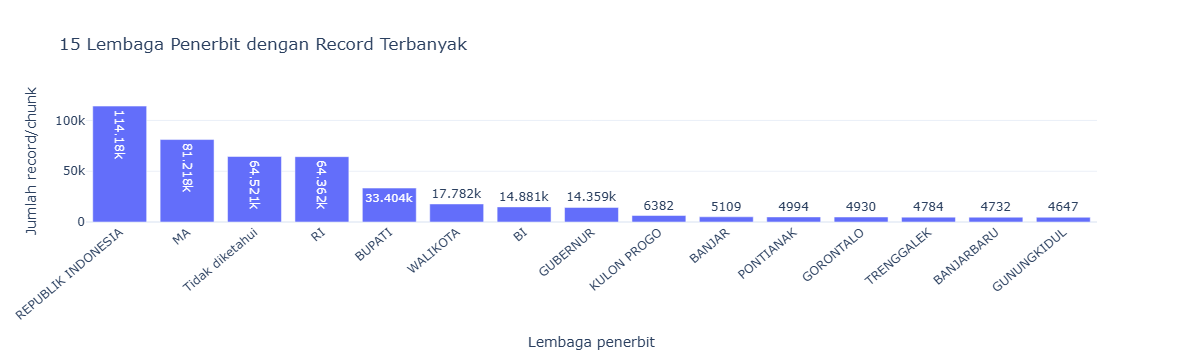

In [10]:
distribusi_lembaga = (
    lf.select(
        pl.col("enacting_body")
        .fill_null("Tidak diketahui")
        .alias("enacting_body")
    )
    .group_by("enacting_body")
    .agg(pl.len().alias("jumlah_record"))
    .sort("jumlah_record", descending=True)
    .head(15)
    .collect(engine="streaming")
)

display(distribusi_lembaga)

fig7 = px.bar(
    x=distribusi_lembaga["enacting_body"].to_list(),
    y=distribusi_lembaga["jumlah_record"].to_list(),
    text_auto=True,
    title="15 Lembaga Penerbit dengan Record Terbanyak",
    labels={
        "x": "Lembaga penerbit",
        "y": "Jumlah record/chunk"
    }
)

fig7.update_layout(
    template="plotly_white",
    xaxis_tickangle=-40
)
fig7.show()


## Bagian 5. Ringkasan Bahan untuk Lima Insight Analitik

Cell berikut menghasilkan angka aktual yang dapat digunakan untuk menulis lima insight. Jangan menyimpulkan sebab-akibat hanya dari grafik deskriptif atau korelasi.


In [11]:
# Insight 1: tahun dengan jumlah record tertinggi
puncak_tahun = (
    data_tahunan
    .sort("jumlah_record", descending=True)
    .head(1)
)

print("INSIGHT 1 - TREN TEMPORAL")
display(puncak_tahun)

# Insight 2: kategori jenis peraturan teratas
total_record_kategori = distribusi_jenis["jumlah_record"].sum()

top_jenis = distribusi_jenis.head(5).with_columns(
    (
        pl.col("jumlah_record")
        / total_record_kategori
        * 100
    ).round(2).alias("persentase_dari_15_kategori_teratas")
)

print("\nINSIGHT 2 - KOMPOSISI JENIS PERATURAN")
display(top_jenis)

# Insight 3: lembaga penerbit teratas
total_record_lembaga = distribusi_lembaga["jumlah_record"].sum()

top_lembaga = distribusi_lembaga.head(5).with_columns(
    (
        pl.col("jumlah_record")
        / total_record_lembaga
        * 100
    ).round(2).alias("persentase_dari_15_lembaga_teratas")
)

print("\nINSIGHT 3 - LEMBAGA PENERBIT")
display(top_lembaga)

# Insight 4: distribusi panjang konten
print("\nINSIGHT 4 - PANJANG KONTEN")
display(statistik_panjang)

# Insight 5: domain dengan rata-rata kompleksitas tertinggi
top_kompleksitas = (
    domain_metrics
    .sort("rata_kompleksitas", descending=True)
    .head(5)
)

print("\nINSIGHT 5 - KOMPLEKSITAS DOMAIN HUKUM")
display(top_kompleksitas)

# Ringkasan status tahun untuk transparansi analisis temporal
status_tahun = (
    lf.group_by("year_status")
    .agg(pl.len().alias("jumlah_record"))
    .sort("jumlah_record", descending=True)
    .collect(engine="streaming")
)

print("\nPEMERIKSAAN STATUS TAHUN")
display(status_tahun)


INSIGHT 1 - TREN TEMPORAL


year,jumlah_record,moving_average_5_tahun,perubahan_dari_tahun_sebelumnya,pertumbuhan_persen
i64,i64,f64,i64,f64
2016,117505,81553.2,28766,32.416412



INSIGHT 2 - KOMPOSISI JENIS PERATURAN


regulation_type,jumlah_record,persentase_dari_15_kategori_teratas
str,u32,f64
"""PERATURAN DAERAH KABUPATEN""",261899,35.02
"""PERATURAN BUPATI""",109002,14.57
"""Tidak diketahui""",79764,10.66
"""PERATURAN DAERAH KOTA""",71978,9.62
"""PERATURAN PEMERINTAH""",46280,6.19



INSIGHT 3 - LEMBAGA PENERBIT


enacting_body,jumlah_record,persentase_dari_15_lembaga_teratas
str,u32,f64
"""REPUBLIK INDONESIA""",114180,25.93
"""MA""",81218,18.45
"""Tidak diketahui""",64521,14.65
"""RI""",64362,14.62
"""BUPATI""",33404,7.59


... (2 outputs left out)


INSIGHT 5 - KOMPLEKSITAS DOMAIN HUKUM


kg_primary_domain,jumlah_record,rata_kompleksitas,rata_authority,rata_legal_richness,rata_completeness
str,u32,f64,f64,f64,f64
"""telecommunications""",66647,0.365469,0.35798,0.252215,0.792112
"""criminal""",9829,0.344174,0.435091,0.214696,0.847553
"""financial""",6414,0.342264,0.426729,0.222973,0.832834
"""administrative""",17396,0.319873,0.38594,0.188167,0.84514
"""tax""",43564,0.317741,0.363787,0.157557,0.839245



PEMERIKSAAN STATUS TAHUN


year_status,jumlah_record
str,u32
"""ok""",747989
"""invalid_sentinel_0000""",567
"""future_year_check""",2


## Bagian 6. Penulisan Lima Insight Analitik

Gunakan tabel dan visualisasi hasil eksekusi untuk mengisi bagian berikut. Angka harus diambil dari output notebook, bukan diperkirakan.

1. **Insight 1 — Tren temporal:** Jelaskan tahun dengan jumlah record tertinggi dan perubahan tren berdasarkan moving average lima tahun. Tegaskan bahwa angka menunjukkan record/chunk, bukan otomatis jumlah dokumen hukum unik.
2. **Insight 2 — Distribusi jenis peraturan:** Jelaskan jenis peraturan yang paling dominan dan perbandingannya dengan kategori lain. Sertakan proporsi berdasarkan output.
3. **Insight 3 — Lembaga penerbit:** Jelaskan lembaga yang paling banyak muncul dalam dataset serta konsentrasi record pada beberapa lembaga teratas.
4. **Insight 4 — Karakteristik konten:** Jelaskan median, persentil ke-90/95, dan rentang panjang konten. Bahas kemungkinan sebaran miring atau ekor panjang tanpa menganggap seluruh pencilan sebagai kesalahan.
5. **Insight 5 — Struktur knowledge graph:** Jelaskan perbedaan rata-rata kompleksitas, authority score, atau richness antar-domain. Jika memakai korelasi, sebutkan hubungan statistik dan hindari klaim sebab-akibat.

### Catatan keterbatasan
- Data geografis/koordinat tidak tersedia pada schema yang diperiksa, sehingga analisis spasial geografis tidak dilakukan.
- `effective_date` masih berbentuk teks berbahasa Indonesia dan memiliki status tanggal tidak diketahui. Analisis temporal utama menggunakan `year` yang sudah dinormalisasi pada Milestone 2.
- Dua record tahun 2030 berstatus `future_year_check` dan tidak dimasukkan ke tren historis utama.
- Tahun sentinel 0000 telah dijadikan null dan ditandai pada Milestone 2.
- Korelasi dan visualisasi deskriptif tidak membuktikan hubungan sebab-akibat.


## Bagian 7. Kesimpulan Milestone 3

Setelah seluruh cell berhasil dijalankan:
- Pastikan enam visualisasi utama tampil.
- Pastikan moving average lima tahun berhasil dihitung.
- Isi lima insight berdasarkan angka aktual.
- Simpan notebook dengan nama `03_advanced_eda.ipynb`.
